# Введение в Pytorch


В этом курсе мы по большей части будем пользоваться pytorch.
Этот фреймворк во многом похож на numpy, главное его отличие в том, что он может считать градиенты с помощью своего autograd модуля. Еще одно отличие - он поддерживает cuda (и другие бэкенды) для повышения производительности.

# Основные операции

In [112]:
import numpy as np
import torch
from matplotlib import pyplot as plt

In [113]:
a = np.random.rand(5, 3)
a

array([[0.78744023, 0.12604721, 0.05514387],
       [0.08951564, 0.50527021, 0.07306924],
       [0.65500278, 0.68899067, 0.36903164],
       [0.34295459, 0.34781977, 0.57356803],
       [0.82275377, 0.52681235, 0.99742379]])

In [114]:
a + 5

array([[5.78744023, 5.12604721, 5.05514387],
       [5.08951564, 5.50527021, 5.07306924],
       [5.65500278, 5.68899067, 5.36903164],
       [5.34295459, 5.34781977, 5.57356803],
       [5.82275377, 5.52681235, 5.99742379]])

In [115]:
a ** 2

array([[0.62006211, 0.0158879 , 0.00304085],
       [0.00801305, 0.25529798, 0.00533911],
       [0.42902864, 0.47470814, 0.13618435],
       [0.11761785, 0.12097859, 0.32898029],
       [0.67692377, 0.27753126, 0.99485422]])

In [116]:
a.shape

(5, 3)

In [117]:
a.flatten()

array([0.78744023, 0.12604721, 0.05514387, 0.08951564, 0.50527021,
       0.07306924, 0.65500278, 0.68899067, 0.36903164, 0.34295459,
       0.34781977, 0.57356803, 0.82275377, 0.52681235, 0.99742379])

In [118]:
a.reshape(-1, 1)

array([[0.78744023],
       [0.12604721],
       [0.05514387],
       [0.08951564],
       [0.50527021],
       [0.07306924],
       [0.65500278],
       [0.68899067],
       [0.36903164],
       [0.34295459],
       [0.34781977],
       [0.57356803],
       [0.82275377],
       [0.52681235],
       [0.99742379]])

In [119]:
b = np.random.rand(7, 5)

In [120]:
a.T @ b.T


array([[1.40918944, 1.49113364, 1.57216769, 1.60068796, 1.50347335,
        1.57261931, 1.58866334],
       [1.34365127, 1.41708504, 1.06179878, 1.00774119, 1.13319476,
        1.10989541, 1.10510626],
       [1.67482882, 1.44889653, 0.94965464, 1.10971908, 1.17218378,
        1.15572165, 0.93024393]])

Задача 1: напишите функцию, которая принимает на вход вектор размера n и возвращает значения функции $2log(x^2) - 1.5 sqrt(x) + x^{1/2}$

In [121]:
def f(x):
    return 2 * np.log(x**2) - 1.5 * np.sqrt(x) + np.sqrt(x)

In [122]:
x = np.array([1.0, 4.0, 9.0, 16.0])
print(f(x))

x = np.array([4.0])
print(f(x))

[-0.5         4.54517744  7.28889831  9.09035489]
[4.54517744]


Задача 2: Посчитайте сумму значений функции из 1 задачи для натуральных чисел с 1 до 300

In [123]:
x = np.arange(1, 301)
f(x).sum()

np.float64(3923.345205492068)

В общем  и целом, синтаксис в torch очень похож на numpy, однако с некоторыми отличиями:

In [124]:
a = torch.rand(5,3)

In [125]:
a**2

tensor([[0.0132, 0.1131, 0.3709],
        [0.9268, 0.4263, 0.3250],
        [0.3623, 0.0269, 0.2071],
        [0.0465, 0.0172, 0.0262],
        [0.9559, 0.4092, 0.4226]])

In [126]:
a.size()

torch.Size([5, 3])

In [127]:
a.flatten()

tensor([0.1149, 0.3363, 0.6090, 0.9627, 0.6529, 0.5701, 0.6019, 0.1641, 0.4551,
        0.2155, 0.1310, 0.1619, 0.9777, 0.6397, 0.6501])

Есть разница между тем, чтобы получить представление тензора или его копию. Самый явный способ получить представление - оператор view. 

In [128]:
b = a.view(-1,1)

In [129]:
a.zero_()

tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])

In [130]:
b

tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]])

In [131]:
a = torch.rand(5,3)

In [132]:
b

tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]])

In [133]:
a = a.resize(5, 3)

In [134]:
a.view(torch.int)

tensor([[1034353552, 1030262928, 1059504936],
        [1043847424, 1047878280, 1062160735],
        [1027231568, 1056976448, 1033169776],
        [1049710050,  996030720, 1059408739],
        [1005884800, 1053020922, 1064467253]], dtype=torch.int32)

In [135]:
a

tensor([[0.0815, 0.0568, 0.6514],
        [0.1795, 0.2396, 0.8097],
        [0.0455, 0.5007, 0.0727],
        [0.2838, 0.0034, 0.6457],
        [0.0075, 0.3825, 0.9472]])

In [136]:
b = a.view(3,5)

Тензор устроен чуть сложнее, чем массив numpy. На самом деле он хранит не только данные, но и другую полезную информацию. Например, каждый тензор находится на своем девайсе. 
Вопрос: Если бы тензор находился не на cpu, то перенос его с gpu на cpu создал бы копию?

Ответ: Да, создалась бы копия, тк у cpu и gpu разная физическая память.

In [137]:
b.device

device(type='cpu')

In [138]:
a.unsqueeze(0)

tensor([[[0.0815, 0.0568, 0.6514],
         [0.1795, 0.2396, 0.8097],
         [0.0455, 0.5007, 0.0727],
         [0.2838, 0.0034, 0.6457],
         [0.0075, 0.3825, 0.9472]]])

In [139]:
b = torch.rand(7,5)

К тензорам применимы различные операции, как поэлементные, так и матричные.

In [140]:
a.T @ b.T

tensor([[0.3228, 0.2727, 0.2681, 0.4098, 0.2443, 0.2414, 0.2706],
        [0.2260, 0.5594, 0.2609, 0.2443, 0.7348, 0.5219, 0.4437],
        [1.4958, 1.4013, 0.9478, 1.4082, 1.3353, 1.4768, 1.5524]])

In [141]:
torch.matmul(b, a)

tensor([[0.3228, 0.2260, 1.4958],
        [0.2727, 0.5594, 1.4013],
        [0.2681, 0.2609, 0.9478],
        [0.4098, 0.2443, 1.4082],
        [0.2443, 0.7348, 1.3353],
        [0.2414, 0.5219, 1.4768],
        [0.2706, 0.4437, 1.5524]])

In [142]:
b = torch.rand(3,1,4,1,5)

In [143]:
b.squeeze().shape

torch.Size([3, 4, 5])

In [144]:
b.squeeze(1).shape

torch.Size([3, 4, 1, 5])

Задача 3. напишите функцию на torch, которая принимает на вход вектор размера n и возвращает значения функции $2log(x^2) - 1.5 sqrt(x) + x^{1/2}$

In [145]:
def f_torch(x):
    return 2 * torch.log(x**2) - 1.5 * torch.sqrt(x) + torch.sqrt(x)

Задача 4: Посчитайте сумму значений функции из 3 задачи для натуральных чисел с 1 до 300

In [146]:
x = torch.arange(1, 301, dtype=torch.float32)
f_torch(x).sum()

tensor(3923.3452)

 Другие варианты создать тензор:

In [147]:
a = torch.empty(5,2)
b = torch.zeros(6,1, dtype=torch.bool)
c = torch.ones_like(b) 

Тензор можно создать и из другого объекта. Как думаете, какой тип будет у результирующего тензора?

In [148]:
d = torch.tensor([5,3.4])

In [149]:
d.dtype

torch.float32

Torch легко переводится в numpy и наоборот. Из-за разницы типов результат не будет идентичным, но он будет достаточно близким к исходному.

In [150]:
a = np.ones((3, 5))
x = torch.ones((3, 5))
np.allclose(x.numpy(), a)

True

Впрочем, если тензор находится на gpu, для начала его необходимо вернуть на cpu. Кроме того, не все типы данных, которые поддерживает torch, например, bf16, поддерживаются numpy, и тогда сначала необходимо привести тензор к нужному типу.

# Градиенты

Одна из основных причин использования PyTorch в глубоком обучении заключается в возможности автоматического получения градиентов для функций практически любой сложности. Мы будем использовать PyTorch преимущественно для реализации нейронных сетей, а они, по сути, представляют собой сложные функции. Если в такой функции используются матрицы коэффициентов, которые мы хотим обучить, то они называются параметрами или просто весами.


Имея на входе данные, мы определяем функцию путем преобразования этих входных данных — как правило, посредством умножения на матрицы весов и сложения с так называемыми векторами смещения (bias vectors). В процессе этих преобразований автоматически формируется вычислительный граф. Этот граф отображает путь от входных данных к выходному результату. PyTorch — это фреймворк, работающий по принципу «define-by-run» (определение в процессе выполнения): это означает, что мы просто выполняем необходимые операции, а PyTorch самостоятельно отслеживает соответствующий граф. Таким образом, в ходе работы создается динамический вычислительный граф. 

Рассмотрим достаточно простой датасет:

In [151]:
x1 = torch.arange(-15, 15, 0.1)
x2 = torch.arange(-15, 15, 0.1) / 5
x = torch.stack([x1, x2], dim=1)
y = x[:,0] * 2. + 0.2 * x[:, 1]**2 - 3 + torch.normal(0., 0.2, (1, 300))

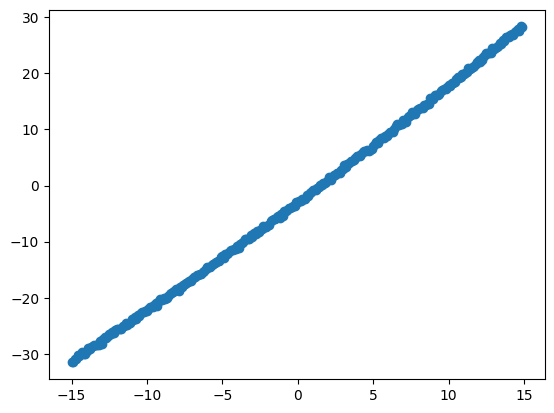

In [152]:
plt.scatter(x[:, 0], y)

Доп.задание. Изобразите поверхность на 3d-графике

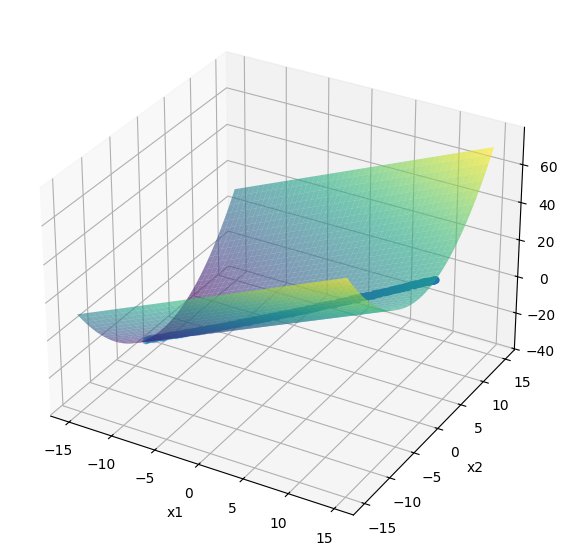

In [153]:
g1 = np.arange(-15, 15, 0.1)
g2 = np.arange(-15, 15, 0.1)
X1, X2 = np.meshgrid(g1, g2)
Y = 2*X1 + 0.2*X2**2 - 3

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X1, X2, Y, cmap='viridis', alpha=0.6)
ax.scatter(x[:,0].numpy(), x[:,1].numpy(), y.squeeze().numpy())
ax.set_xlabel('x1'); ax.set_ylabel('x2'); ax.set_zlabel('y')
plt.show()


Прежде всего необходимо указать, какие тензоры будут требовать градиенты, с помощью параметра requires_grad. Если requires_grad=False, то это просто массив с числами, посчитать dx/dy не выйдет (по умолчанию).

Если же requires_grad=True, то фреймворк будит учитывать этот тензор при построении графа вычислений производной.
Например, станет возможно посчитать d(sin(log(x**2) - 3x))/dx.


Итак, как PyTorch строит вычислительный граф и вычисляет градиенты? Вершинами графа являются объекты класса torch.autograd.Node, например, AddBackward, MulBackward - это результаты выполнения операций. Ребрами же являются сами тензоры. Соответственно, у каждого тензора,  для которого требуется вычисление градиентов, есть ссылка на функцию .grad_fn, которая градиент создала, и значение самих частных производных (тоже тензор) .grad. Если градиенты неприменимы, то эта функция станет None.



In [155]:
a = torch.rand(5,2, requires_grad=True)
b = torch.rand(2, 1, requires_grad=True)

In [156]:
mult_res = a @ b
res = mult_res.sum()
res

tensor(0.7972, grad_fn=<SumBackward0>)

In [157]:
mult_res

tensor([[0.2413],
        [0.0762],
        [0.2525],
        [0.1246],
        [0.1025]], grad_fn=<MmBackward0>)

In [158]:
mult_res.grad_fn.next_functions

((<AccumulateGrad at 0x20c52b63e20>, 0),
 (<AccumulateGrad at 0x20c4f998100>, 0))

In [159]:
print(a.grad)

None


А как же получить значения градиентов? Тензоры что-то содержат, операции все известны. На самом деле еще при вычислении значения выражения уже известно, какие операции производятся, поэтому и производную можно посчитать. То, как конкретно это делается, вы узнаете на лекции по backpropagation.

In [160]:
res.backward()

In [161]:
b.grad.data

tensor([[2.0090],
        [2.3760]])

In [162]:
mult_res.grad

C:\Users\Lada\AppData\Local\Temp\ipykernel_20352\6217836.py:1: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more informations. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\build\aten\src\ATen/core/TensorBody.h:494.)
  mult_res.grad


Граф перестраивается на каждом проходе. Это удобно - мы не зависим от размеров семпплов и батчей, но дает оверхед, который может стать значительным у больших моделей. 

Начиная с PyTorch 2.0 появилась возможность получать статические вычислительные графы, что позволяет сильно ускорить обучение, об этом детально мы, возможно, поговорим позже. Пока что просто помните, что если вам необходимо ускорить инференс или обучение модели, один из простейших вариантов - использовать torch.compile и статические графы. В таком случае, многие операции на ускорителе можно оптимизировать, а лишние этапы перестройки опустить.


Перейдем к нашим данным. Попробуем обучить простую линейную модель с помощью градиентного спуска.

In [164]:
w = torch.rand(1, 2, requires_grad=True)
b = torch.rand(1, requires_grad=True)
y_pred = w @ x.T + b  
loss = torch.mean((y_pred - y) ** 2)
loss.backward()

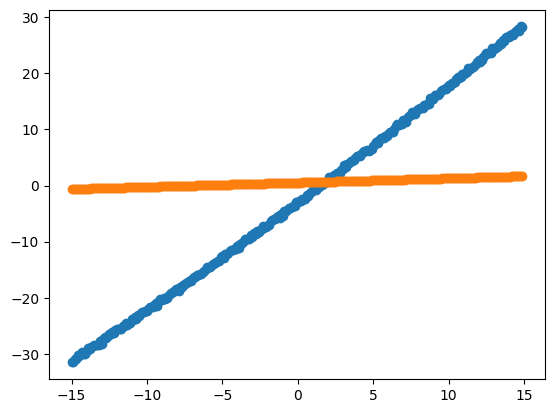

In [165]:
plt.scatter(x[:, 0], y)
plt.scatter(x[:, 0], y_pred.detach().numpy())

Пока не слишком похоже на то, что мы хотим. Для того, чтобы изменения применились, нужно сделать шаг градиентного спуска.

**Задание**. Проведите 100 итераций градиентного спуска для данного набора.
Для этого надо вспомнить, как выглядит этот алгоритм для линейной регрессии

In [166]:
w.grad

tensor([[-288.6362,  -57.7272]])

Weights: tensor([[2.3952, 1.1949]], requires_grad=True)
Gradients: tensor([[-169.7204,  -33.9441]])
Gradients: tensor([[0., 0.]])
Weights: tensor([[1.4447, 1.0048]], requires_grad=True)
Gradients: tensor([[95.0549, 19.0110]])
Gradients: tensor([[0., 0.]])
Weights: tensor([[1.9770, 1.1112]], requires_grad=True)
Gradients: tensor([[-53.2287, -10.6457]])
Gradients: tensor([[0., 0.]])
Weights: tensor([[1.6788, 1.0516]], requires_grad=True)
Gradients: tensor([[29.8152,  5.9630]])
Gradients: tensor([[0., 0.]])
Weights: tensor([[1.8458, 1.0850]], requires_grad=True)
Gradients: tensor([[-16.6924,  -3.3385]])
Gradients: tensor([[0., 0.]])
Weights: tensor([[1.7522, 1.0663]], requires_grad=True)
Gradients: tensor([[9.3534, 1.8707]])
Gradients: tensor([[0., 0.]])
Weights: tensor([[1.8046, 1.0767]], requires_grad=True)
Gradients: tensor([[-5.2333, -1.0467]])
Gradients: tensor([[0., 0.]])
Weights: tensor([[1.7752, 1.0709]], requires_grad=True)
Gradients: tensor([[2.9357, 0.5871]])
Gradients: tensor(

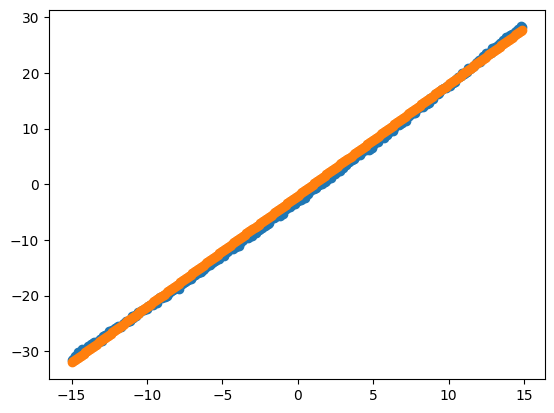

In [174]:
w = torch.rand(1, 2, requires_grad=True)
b = torch.rand(1, requires_grad=True)
lr = 0.01

for i in range(100):
    
    y_pred =  w @ x.T + b
    loss = torch.mean((y_pred - y) ** 2)
    loss.backward()
    with torch.no_grad():
        # torch.no_grad() выключает обернутую часть из графа
        # Почему мы не можем сделать так? - это будет новый тензор, он не будет листом графа, а старый лист w потеряется => обучение сломается.
        #  w  = w  - 0.1 * w.grad
        #  b  = b  - 0.1 * b.grad

        w -= lr * w.grad
        b -= lr * b.grad

        print(f"Weights: {w}")

    print(f"Gradients: {w.grad}")
    # На каждой итерации нужно занулить градиенты 
    # - иначе они будут копиться и приведут к непредвиденным результатам 
    # Это делают через  grad.data.zero_()

    w.grad.zero_()
    b.grad.zero_()

    print(f"Gradients: {w.grad}")
plt.scatter(x[:, 0], y)
plt.scatter(x[:, 0], y_pred.detach().numpy())

# Пайплайн обучения

Кроме собственно тензоров, функций потерь и градиентов, основные составляющие библиотеки как и всегда - датасеты и модели. При этом торч позволяет довольно свободно составлять и то, и другое из простейших блоков, лишь поддерживая необходимые интерфейсы.

Импортируем torch.nn - тут находятся классы, реализующие слои, лоссы, функции ошибок и тд. 
Для примера я использую стандартный датасет для компьютерного зрения - MNIST - содержащий цифры от 0 до 9 в разном написании. Поэтому импортируются некоторые подмодули torchvision


In [175]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.transforms import ToTensor
from matplotlib import pyplot as plt

In [176]:
import os
import pandas as pd
from torchvision.io import read_image


# Создание датасета

Pytorch позволяет использовать открытые датасеты с хаба. Они все являются подклассами `torch.utils.data.Dataset` и имплементируют методы, специфичные для этого класса данных. Обычно они используются для прототипирования и бенчмаркинга и могут быть загружены по необходимости. Однако если для задачи необxодимо что-то кроме предполагаемой разработчиками функциональности, нужно либо отнаследовать один из них, либо напрямую `torch.utils.data.Dataset`.

Давайте загрузим FashionMNIST (https://github.com/zalandoresearch/fashion-mnist) - один из таких простых бенчмарк-датасетов для компьютерного зрения. Каждый семпл - это черно-белое изображение размером 28х28 с каким-то предметом одежды и ассоциированным классом. Всего набор содержит 60000 + 10000 изображений и 10 классов.


In [180]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

# Download test data from open datasets.
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

100%|██████████| 29.5k/29.5k [00:00<00:00, 16.7MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 7.26MB/s]
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]


In [182]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}

In [183]:
def plot_samples(data, labels_map, cols=3, rows=3):
    figure = plt.figure(figsize=(8, 8))
    for i in range(1, cols * rows + 1):
        sample_idx = torch.randint(len(data), size=(1,)).item()
        img, label = data[sample_idx]
        figure.add_subplot(rows, cols, i)
        if type(label) == torch.Tensor:
            plt.title(labels_map[label.item()])
        else:
            plt.title(labels_map[label])
        plt.axis("off")
        plt.imshow(img.squeeze(), cmap="gray")
    plt.show()

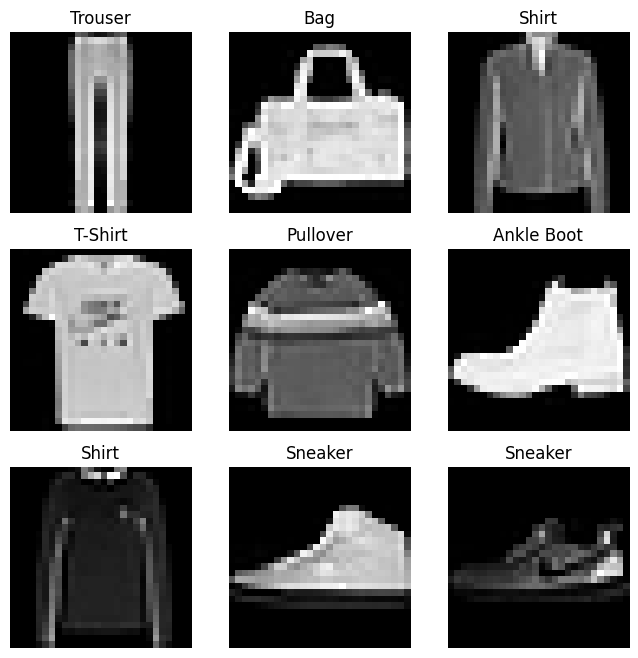

In [184]:
plot_samples(train_data, labels_map, cols=3, rows=3)

Каждый датасет в Pytorch должен наследоваться от класса Dataset и обязательно имплементировать методы `__init__, __len__, __getitem__`. В `__init__` обычно кроме прочего определяются трансформации, которые будут применяться к данным. Это может быть преобразование PIL.Image в тензоры, добавление шума, сдвиги и т.д. 
Pytorch предоставляет большое количество трансформаций, но наиболее популярная и удобная библиотека, реализующая трансформации для изображений - *albumentations*. 

`__len__` - должна возвращать размер датасета (например, чисо строк в файле с аннотациями)

`__getitem__` - должен возвращать семпл данных, например, вектор признаков и y. Однако он может возвращать еще и дополнительную информацию, например, y может состоять из набора bboxoв и  сегментационных масок для детекции, класса изображения итп. Обычно возвращается tuple. В целом, возвращаться может любая структура, которую можно представить как набор тензоров, соответствующих одному семплу и входу модели.
Внутри этого метода может происходить загрузка семпла, его трансформации и другие необходимые манипуляции. Очевидно, что он может возвращать не только изображение, но и любые другие данные, и временные ряды, и табличные данные, и облака точек, и другое. 


Давайте реализуем такой датасет для FashionMNIST. Конечно, можно было бы спокойно использовать встроенный, но так не интересно )

In [185]:
from torchvision.datasets.mnist import read_image_file, read_label_file

In [186]:
class FashionMNISTDataset(Dataset):
    def __init__(self, file_dir, train=True, transform=None, target_transform=None):
        self.transform = transform
        self.target_transform = target_transform
        self.train = train
        image_file = f"{'train' if self.train else 't10k'}-images-idx3-ubyte"
        self.data = read_image_file(os.path.join(file_dir, image_file))

        label_file = f"{'train' if self.train else 't10k'}-labels-idx1-ubyte"
        self.targets = read_label_file(os.path.join(file_dir, label_file))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image = self.data[idx]
        label = self.targets[idx]
        
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label

Проинициализируйте ваш новый датасет так же, как и ранее встроенный.

In [189]:
train_data = FashionMNISTDataset("data/FashionMNIST/raw", train=True, transform=None)
test_data  = FashionMNISTDataset("data/FashionMNIST/raw", train=False, transform=None)

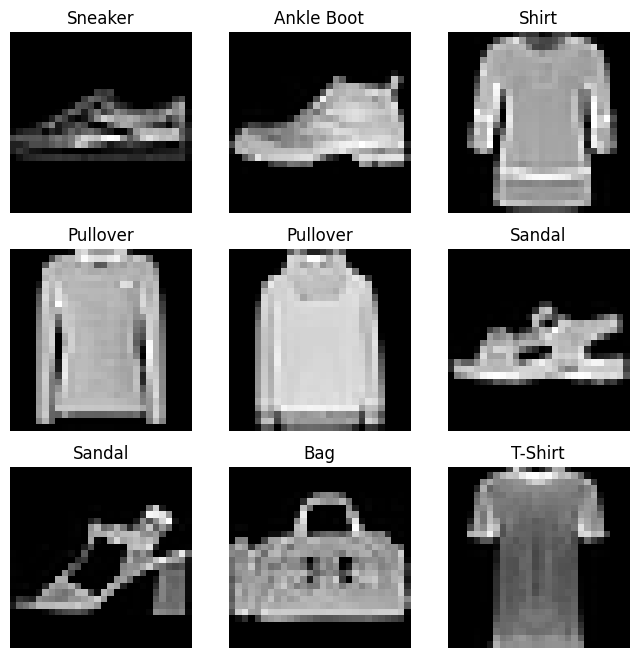

In [190]:
plot_samples(train_data, labels_map, cols=3, rows=3)

Датасет возвращает один семпл за раз, однако часто наши мощности позволяют обрабатывать больше данных. При работе с таблицами модель получает на вход вообще весь набор сразу или достаточно большими порциями. Когда речь заходит о тензорах и наборах с сотнями тысяч и даже миллионами семплов, это невозможно. На помощь приходит батчевая обработка, когда из датасета берутся небольшие порции данных за раз (используя индекс). За соединение семплов во вход модели отвечает класс DataLoader. Каждую эпоху данные шаффлятся, чтобы уменьшить переобучение. 

In [191]:
train_dataloader = DataLoader(train_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

Feature batch shape: torch.Size([64, 28, 28])
Labels batch shape: torch.Size([64])


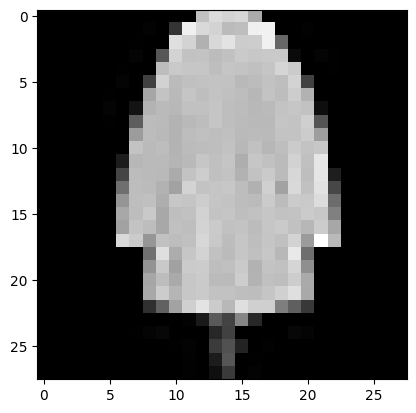

Label: 4


In [192]:
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].squeeze().reshape(28,28)
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

Глубокое обучение чаще всего связывают с GPU, и не зря. Имея дело с тензорами и тензорными вычислениями, мы производим огромное количество элементарных операций. Каждое ядро CPU способно произвести только одно вычисление за такт. GPU был создан для обработки графики, где требуется также большое количество простых вычислений, и поэтому может ускорить обработку данных в тысячи раз. Это все должно быть хорошо Вам известно из других курсов)

К сожалению, часто компьютер не поддерживает вычисления на GPU, например, у него просто нет дискретной видеокарты. Pytorch позволяет проводить все операции на CPU, так что его можно использовать где угодно.



In [193]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")


Using cpu device


*Дополнительное задание: адаптируйте весь код для `accelerate`. Это очень удобная библиотека для адаптации PyTorch кода для любой распределенной конфигурации. Кроме того, она позволяет упростить работу, даже если нам нужно перенести вычисления на GPU или CPU, автоматизируя этот процесс (иначе нам нужно постоянно вызывать `.to(device)`)*
*Для этого импортируйте нужный Accelerator из accelerate. Далее достаточно вызвать accelerator.prepare(elements)*

Теперь создадим класс модели и интстанциируем её. В данном случае это простой перцептрон с тремя слоями. Однако модель может быть сколько угодно сложной. Главное, чтобы она наследовала класс `nn.Module`. Более того, можно написать любой слой собственноручно, также отнаследовав этот класс.
Каждая модель должна имплементировать два метода - `__init__` и `forward(self, *args, **kwargs)`. В первом обычно задается ее структура и другие параметры. Модель  может даже содержать другие модели!

`forward` получает на вход Х, но он может получать несколько разных входов, маски и тд. Обычно возвращаются либо выходы с последнего слоя (один или несколько). Но, например, стандартные модели детекции возвращают в режиме обучения значение лосса, а непосредственные предсказания только в режиме тестирования.

Вызывая `model(data)`, на самом деле мы вызываем именно метод `forward`

Для того, чтобы понять, как устроен слой в Pytorch, создадим простой слой для превращения изображения в вектор.
Пусть это будет класс MyFlatten. Изображения (и, что более актуально, промежуточные представления или, иными словами, карты, внутри модели) изначально имеют размер N x C x H x W, где:

N - число семплов в батче
C - число каналов на входе в конкретный слой. Если вход с 3 каналами, это 3, но в середине модели это может быть любое число, например, 128.
H - высота карты
W - ширина карты

Когда мы делаем что-то вроде двумерной свертки, это стандартное представление данных, которое позволяет восстановить пространственные зависимости между элементами карты. Однако, когда мы используем полносвязные модели, каждый семпл представлен единым вектором. В простом случае больше не нужно разделять разные каналы, строки и столбцы данных. Таким образом, мы используем операцию "вытянуть в вектор", чтобы превратить значения C x H x W в представление C * H * W. 

**Задание**: допишите класс MyFlatten. Этот слой при вызове должен принимать на вход тензор размера B x C x H x W и возвращать тензор размера B x [C * H * W]. Пример: батч картинок 2 x 3(rgb) x 16(h) x 16(w)] -> 2 x 768

In [199]:
class MyFlatten(nn.Module):
    def forward(self, x):
        return x.view(x.size(0), -1)

In [213]:
class NeuralNetwork(nn.Module):
    def __init__(self, use_log_softmax=False):
        super().__init__()
        self.flatten = MyFlatten()
        self.use_log_softmax = use_log_softmax 
        self.fc = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )
        self.log_softmax = nn.LogSoftmax(dim=1)

    def forward(self, x):
        x = self.flatten(x)
        logits = self.fc(x)
        if self.use_log_softmax:
            return self.log_softmax(logits)
        return logits

model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (flatten): MyFlatten()
  (fc): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
  (log_softmax): LogSoftmax(dim=1)
)


Слои: http://pytorch.org/docs/nn.html

Активации: http://pytorch.org/docs/nn.html#non-linear-activations

Зададим функцию ошибки и оптимизатор. Функция ошибки также наследуется от torch.nn.Module и может быть стандартной, состоять как из нескольких стандартных функций или их модификаций. Большое количество функций ошибки уже реализовано в Pytorch.

Внутри каждой итерации обучения оптимизация происходит в три этапа:
Вызов optimizer.zero_grad() для обнуления градиентов параметров модели. Градиенты по умолчанию складываются; чтобы избежать двойного подсчета, мы явно обнуляем их на каждой итерации.

Получение градиентов для каждого веса с помощью loss.backward().
Как только мы получили наши градиенты, остается вызвать optimizer.step(), чтобы изменить параметры в соответствии с нашим алгоритмом оптимизации. 

In [214]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

Задание: 
1) Выберите как минимум еще 2 разные функции ошибки из https://pytorch.org/docs/stable/nn.html#loss-functions и обучите модель с ними
2) Выберите как минимум еще 1 оптимизатор из https://pytorch.org/docs/stable/optim.html и обучите каждую из моделей с ним

В результате у вас должна получиться таблица с лучшими значениями лосса для каждого случая для обучения и теста. В идеале оформите их в виде pandas.DataFrame или другой таблицы с удобным выводом.

In [215]:
import pandas as pd

def experiment(loss_name, opt_name, epochs=5, lr=1e-3, verbose=True):
    model = NeuralNetwork(use_log_softmax=(loss_name == "NLL")).to(device)
    loss_fn = {"CE": nn.CrossEntropyLoss(), "NLL": nn.NLLLoss()}[loss_name]
    opt_cls = {"SGD": lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9),
               "Adam": lambda p: torch.optim.Adam(p, lr=lr)}[opt_name]
    optimizer = opt_cls(model.parameters())

    best_train_loss, best_test_loss, best_test_acc = float('inf'), float('inf'), 0.0
    train_hist, test_hist = [], []

    for epoch in range(epochs):
        # train
        model.train()
        tr_loss = 0.0
        for inputs, targets in train_dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(inputs), targets)
            loss.backward()
            optimizer.step()
            tr_loss += loss.item()
        tr_loss /= len(train_dataloader)

        # test
        model.eval()
        te_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, targets in test_dataloader:
                inputs, targets = inputs.to(device), targets.to(device)
                preds = model(inputs)
                te_loss += loss_fn(preds, targets).item()
                correct += (preds.argmax(1) == targets).sum().item()
                total += targets.size(0)
        te_loss /= len(test_dataloader)
        te_acc = correct / total

        train_hist.append(tr_loss)
        test_hist.append(te_loss)
        best_train_loss = min(best_train_loss, tr_loss)
        best_test_loss  = min(best_test_loss,  te_loss)
        best_test_acc   = max(best_test_acc,   te_acc)

        if verbose:
            print(f"epoch {epoch+1}: train_loss={tr_loss:.4f}, test_loss={te_loss:.4f}, acc={te_acc:.4f}")

    return {
        "loss": loss_name, "optimizer": opt_name,
        "best_train_loss": round(best_train_loss, 4),
        "best_test_loss":  round(best_test_loss,  4),
        "best_test_acc":   round(best_test_acc,   4),
    }, train_hist, test_hist


results, histories = [], {}
for loss_name in ["CE", "NLL"]:
    for opt_name in ["SGD", "Adam"]:
        key = f"{loss_name}+{opt_name}"
        print(f"\n=== {key} ===")
        r, tr_h, te_h = experiment(loss_name, opt_name, epochs=5)
        results.append(r)
        histories[key] = (tr_h, te_h)

df = pd.DataFrame(results)
print("\n", df)


=== CE+SGD ===
epoch 1: train_loss=1.3123, test_loss=0.7868, acc=0.7041
epoch 2: train_loss=0.6782, test_loss=0.6216, acc=0.7790
epoch 3: train_loss=0.5664, test_loss=0.5585, acc=0.8061
epoch 4: train_loss=0.5144, test_loss=0.5199, acc=0.8163
epoch 5: train_loss=0.4837, test_loss=0.5027, acc=0.8212

=== CE+Adam ===
epoch 1: train_loss=0.4892, test_loss=0.4177, acc=0.8415
epoch 2: train_loss=0.3574, test_loss=0.3992, acc=0.8554
epoch 3: train_loss=0.3212, test_loss=0.3512, acc=0.8733
epoch 4: train_loss=0.2967, test_loss=0.3594, acc=0.8704
epoch 5: train_loss=0.2766, test_loss=0.3525, acc=0.8740

=== NLL+SGD ===
epoch 1: train_loss=1.3637, test_loss=0.8134, acc=0.6925
epoch 2: train_loss=0.6909, test_loss=0.6392, acc=0.7791
epoch 3: train_loss=0.5740, test_loss=0.5599, acc=0.8027
epoch 4: train_loss=0.5166, test_loss=0.5306, acc=0.8124
epoch 5: train_loss=0.4855, test_loss=0.4960, acc=0.8242

=== NLL+Adam ===
epoch 1: train_loss=0.4905, test_loss=0.3982, acc=0.8565
epoch 2: train_loss=

Обучим модель. Для этого нужно описать цикл обучения и проверки модели. В наивном случае создается две функции train и validate (test), которые вызываются в цикле по эпохам. В дальнейшем, при усложнении прохода по эпохе, может появиться метод train, целый класс Trainer и т.д. Пока что реализуем наивный вариант.

In [220]:
def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch_idx, (inputs, targets) in enumerate(dataloader):
        inputs, targets = inputs.to(device), targets.to(device)

        # Compute prediction error
        preds = model(inputs)
        loss = loss_fn(preds, targets)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if batch_idx % 100 == 0:
            loss, current = loss.item(), (batch_idx + 1) * len(inputs)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
            
        ''' Чтобы сделать задание со сравнением лоссов, не забудьте 
            реализовать трекинг минимального лосса  '''

In [221]:
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, num_correct = 0, 0
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)

            preds = model(inputs)
            test_loss += loss_fn(preds, targets).item()
            num_correct += (preds.argmax(1) == targets).type(torch.float).sum().item()
    test_loss /= num_batches
    correct = num_correct / size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

    return test_loss, correct

Задание: Добавьте метрики precision и recall для проверки

In [227]:
from sklearn.metrics import precision_score, recall_score

def test_with_metrics(dataloader, model, loss_fn):
    model.eval()
    all_preds, all_targets = [], []
    test_loss = 0.0
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            preds = model(inputs)
            test_loss += loss_fn(preds, targets).item()
            all_preds.append(preds.argmax(1).cpu())
            all_targets.append(targets.cpu())

    all_preds = torch.cat(all_preds).numpy()
    all_targets = torch.cat(all_targets).numpy()

    acc = (all_preds == all_targets).mean()
    precision = precision_score(all_targets, all_preds, average='macro', zero_division=0)
    recall = recall_score(all_targets, all_preds, average='macro', zero_division=0)

    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {precision:.4f} (macro)")
    print(f"Recall:    {recall:.4f} (macro)")

    return acc, precision, recall

In [228]:
model = NeuralNetwork().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-2, momentum=0.9)

epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    test_with_metrics(test_dataloader, model, loss_fn)

Epoch 1
-------------------------------
loss: 2.306453
loss: 0.944119
loss: 0.716563
loss: 0.453891
loss: 0.490170
loss: 0.384344
loss: 0.525433
loss: 0.685026
loss: 0.498280
loss: 0.536206
Accuracy:  0.8293
Precision: 0.8327 (macro)
Recall:    0.8293 (macro)
Epoch 2
-------------------------------
loss: 0.530639
loss: 0.427790
loss: 0.369236
loss: 0.489844
loss: 0.469239
loss: 0.334993
loss: 0.440371
loss: 0.379674
loss: 0.453050
loss: 0.430659
Accuracy:  0.8522
Precision: 0.8544 (macro)
Recall:    0.8522 (macro)
Epoch 3
-------------------------------
loss: 0.303280
loss: 0.417954
loss: 0.231747
loss: 0.211099
loss: 0.337417
loss: 0.323041
loss: 0.400880
loss: 0.508632
loss: 0.144309
loss: 0.437838
Accuracy:  0.8594
Precision: 0.8597 (macro)
Recall:    0.8594 (macro)
Epoch 4
-------------------------------
loss: 0.448646
loss: 0.366561
loss: 0.302779
loss: 0.241256
loss: 0.500414
loss: 0.362966
loss: 0.275174
loss: 0.236993
loss: 0.331082
loss: 0.276408
Accuracy:  0.8630
Precision: 0

Осталось сохранить модель для дальнейшего использования. 

In [224]:
torch.save(model.state_dict(), "best_model.pth")

Какая точность получилась? 

Дополнительное задание:

In [229]:
from accelerate import Accelerator

accelerator = Accelerator()
device = accelerator.device
print(f"Using {device} device")

train_dataloader = DataLoader(train_data, batch_size=64, shuffle=True)
test_dataloader  = DataLoader(test_data,  batch_size=64, shuffle=False)

model = NeuralNetwork()

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-2, momentum=0.9)

model, optimizer, train_dataloader, test_dataloader = accelerator.prepare(
    model, optimizer, train_dataloader, test_dataloader
)

def train(dataloader, model, loss_fn, optimizer):
    model.train()
    for batch_idx, (inputs, targets) in enumerate(dataloader):
        preds = model(inputs)
        loss = loss_fn(preds, targets)

        optimizer.zero_grad()
        accelerator.backward(loss)
        optimizer.step()

        if batch_idx % 100 == 0:
            print(f"loss: {loss.item():>7f}")

def test(dataloader, model, loss_fn):
    model.eval()
    test_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for inputs, targets in dataloader:
            preds = model(inputs)
            test_loss += loss_fn(preds, targets).item()
            preds, targets = accelerator.gather_for_metrics((preds, targets))
            correct += (preds.argmax(1) == targets).sum().item()
            total += targets.size(0)
    print(f"Accuracy: {100 * correct / total:.1f}%, Avg loss: {test_loss / len(dataloader):.4f}")

for i in range(10):
    print(f"Epoch {i+1}")
    train(train_dataloader, model, loss_fn, optimizer)
    test(test_dataloader, model, loss_fn)

Using cpu device
Epoch 1
loss: 2.289492
loss: 0.832631
loss: 0.821541
loss: 0.688560
loss: 0.526077
loss: 0.497026
loss: 0.349548
loss: 0.450454
loss: 0.308007
loss: 0.368552
Accuracy: 81.0%, Avg loss: 0.5223
Epoch 2
loss: 0.531363
loss: 0.345160
loss: 0.675049
loss: 0.390838
loss: 0.371422
loss: 0.389034
loss: 0.446990
loss: 0.395673
loss: 0.318223
loss: 0.226852
Accuracy: 83.8%, Avg loss: 0.4603
Epoch 3
loss: 0.490126
loss: 0.448815
loss: 0.462128
loss: 0.339359
loss: 0.297195
loss: 0.324517
loss: 0.324160
loss: 0.366744
loss: 0.389216
loss: 0.358567
Accuracy: 85.8%, Avg loss: 0.3870
Epoch 4
loss: 0.217420
loss: 0.379874
loss: 0.240066
loss: 0.412036
loss: 0.278218
loss: 0.387430
loss: 0.589506
loss: 0.530863
loss: 0.318119
loss: 0.340663
Accuracy: 86.6%, Avg loss: 0.3594
Epoch 5
loss: 0.125464
loss: 0.426719
loss: 0.331330
loss: 0.371195
loss: 0.232530
loss: 0.285819
loss: 0.392269
loss: 0.296969
loss: 0.280145
loss: 0.432800
Accuracy: 86.6%, Avg loss: 0.3641
Epoch 6
loss: 0.300656


Задание: Перепишите датасет FashionMNISTDataset так, чтобы он возвращал вектор вместо матрицы и мою модель без слоя MyFlatten(). Запустите обучение заново. Какая точность получилась теперь?

In [230]:
class FashionMNISTDataset(Dataset):
    def __init__(self, file_dir, train=True, transform=None, target_transform=None):
        self.transform = transform
        self.target_transform = target_transform
        self.train = train
        image_file = f"{'train' if self.train else 't10k'}-images-idx3-ubyte"
        self.data = read_image_file(os.path.join(file_dir, image_file))
        label_file = f"{'train' if self.train else 't10k'}-labels-idx1-ubyte"
        self.targets = read_label_file(os.path.join(file_dir, label_file))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image = self.data[idx].float().view(-1) / 255.0
        label = self.targets[idx]
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label

In [231]:
class NeuralNetworkFlat(nn.Module):
    def __init__(self, use_log_softmax=False):
        super().__init__()
        self.use_log_softmax = use_log_softmax
        self.fc = nn.Sequential(
            nn.Linear(784, 512), nn.ReLU(),
            nn.Linear(512, 512), nn.ReLU(),
            nn.Linear(512, 10)
        )
        self.log_softmax = nn.LogSoftmax(dim=1)

    def forward(self, x):
        logits = self.fc(x)
        if self.use_log_softmax:
            return self.log_softmax(logits)
        return logits

In [232]:
train_data = FashionMNISTDataset("data/FashionMNIST/raw", train=True)
test_data  = FashionMNISTDataset("data/FashionMNIST/raw", train=False)

train_dataloader = DataLoader(train_data, batch_size=64, shuffle=True)
test_dataloader  = DataLoader(test_data,  batch_size=64, shuffle=False)

model = NeuralNetworkFlat().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-2, momentum=0.9)

for t in range(10):
    print(f"Epoch {t+1}")
    train(train_dataloader, model, loss_fn, optimizer)
    test_with_metrics(test_dataloader, model, loss_fn)

Epoch 1
loss: 2.312120
loss: 0.861884
loss: 0.591403
loss: 0.555369
loss: 0.634799
loss: 0.485756
loss: 0.698836
loss: 0.509043
loss: 0.400593
loss: 0.439411
Accuracy:  0.8312
Precision: 0.8342 (macro)
Recall:    0.8312 (macro)
Epoch 2
loss: 0.446815
loss: 0.485277
loss: 0.284972
loss: 0.344109
loss: 0.482753
loss: 0.419464
loss: 0.212131
loss: 0.495200
loss: 0.398980
loss: 0.462568
Accuracy:  0.8476
Precision: 0.8478 (macro)
Recall:    0.8476 (macro)
Epoch 3
loss: 0.353653
loss: 0.324311
loss: 0.285740
loss: 0.619134
loss: 0.314885
loss: 0.402738
loss: 0.281210
loss: 0.237980
loss: 0.337240
loss: 0.196052
Accuracy:  0.8585
Precision: 0.8602 (macro)
Recall:    0.8585 (macro)
Epoch 4
loss: 0.644575
loss: 0.361631
loss: 0.292253
loss: 0.412688
loss: 0.290945
loss: 0.368769
loss: 0.286030
loss: 0.349846
loss: 0.240819
loss: 0.187368
Accuracy:  0.8614
Precision: 0.8643 (macro)
Recall:    0.8614 (macro)
Epoch 5
loss: 0.276642
loss: 0.320782
loss: 0.280273
loss: 0.352456
loss: 0.367593
loss:

Задание: придумайте свою собственную модель. Улучшите результат (но без сверток)

In [233]:
class MyModel(nn.Module):
    def __init__(self, hidden=512, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(784, hidden),
            nn.BatchNorm1d(hidden),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden, hidden),
            nn.BatchNorm1d(hidden),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden, hidden // 2),
            nn.BatchNorm1d(hidden // 2),
            nn.ReLU(),

            nn.Linear(hidden // 2, 10)
        )

    def forward(self, x):
        return self.net(x)

In [234]:
model = MyModel(hidden=512, dropout=0.3).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)

epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}")
    train(train_dataloader, model, loss_fn, optimizer)
    test_with_metrics(test_dataloader, model, loss_fn)
    scheduler.step()

Epoch 1
loss: 2.454632
loss: 0.707096
loss: 0.357927
loss: 0.682141
loss: 0.419547
loss: 0.626552
loss: 0.417464
loss: 0.308845
loss: 0.396250
loss: 0.423815
Accuracy:  0.8582
Precision: 0.8582 (macro)
Recall:    0.8582 (macro)
Epoch 2
loss: 0.326524
loss: 0.505753
loss: 0.504963
loss: 0.281394
loss: 0.422156
loss: 0.415530
loss: 0.481266
loss: 0.453869
loss: 0.300738
loss: 0.338830
Accuracy:  0.8673
Precision: 0.8687 (macro)
Recall:    0.8673 (macro)
Epoch 3
loss: 0.430294
loss: 0.401416
loss: 0.381024
loss: 0.285564
loss: 0.298016
loss: 0.182070
loss: 0.509585
loss: 0.522852
loss: 0.255275
loss: 0.385582
Accuracy:  0.8670
Precision: 0.8674 (macro)
Recall:    0.8670 (macro)
Epoch 4
loss: 0.265195
loss: 0.298268
loss: 0.308452
loss: 0.174928
loss: 0.252973
loss: 0.296014
loss: 0.438121
loss: 0.462345
loss: 0.333416
loss: 0.297834
Accuracy:  0.8782
Precision: 0.8795 (macro)
Recall:    0.8782 (macro)
Epoch 5
loss: 0.438592
loss: 0.208181
loss: 0.169237
loss: 0.260132
loss: 0.198772
loss:

При подборе гиперпараметров (это те параметры, которые не обучаются, например, lr) и обучении модели помните:
1. Если параметры выбраны хорошо, улучшение видно уже после нескольких сотен итераций.
2. Настраивайте гиперпараметры от грубых значений к точным: начните с тестирования большого диапазона гиперпараметров всего за несколько итераций обучения, чтобы найти комбинации параметров, которые вообще работают.
3. После того, как вы нашли несколько наборов параметров, которые, по-видимому, работают, выполните более тщательный поиск по этим параметрам. Возможно, вам придется тренировать модель большее число эпох.
4. Нужно использовать валидационный набор для поиска. Этот набор нужно выделить из тренировочного и вызывать на нем функцию test.